# Assignment 2

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

### Recursive Fibonacci


In [6]:
def fibonacci_recursive(n):
    if n <= 1:
        return n
    return fibonacci_recursive(n - 1) + fibonacci_recursive(n - 2)

### Iterative Fibonacci

In [10]:
def fibonacci_iterative(n):
    a, b = 0, 1
    
    for _ in range(n):
        a, b = b, a + b
    
    return a

### Dynamic Programming Fibonacci


In [9]:
def fibonacci_dp(n):
    if n <= 1:
        return n
    
    dp = [0] * (n + 1)
    dp[1] = 1
    
    for i in range(2, n + 1):
        dp[i] = dp[i - 1] + dp[i - 2]
    
    return dp[n]

In [11]:
n = 10
print("Recursive:", fibonacci_recursive(n))
print("Iterative:", fibonacci_iterative(n))
print("Dynamic Programming:", fibonacci_dp(n))

Recursive: 55
Iterative: 55
Dynamic Programming: 55


### Experimental Analysis of Fibonacci Execution Time

In [13]:
import time

n_values = [10, 20, 30, 40]

fibonacci_algorithms = {
    "Recursive": fibonacci_recursive,
    "Iterative": fibonacci_iterative,
    "Dynamic Programming": fibonacci_dp
}

fibonacci_time_results = []

for n in n_values:
    for algorithm_name, algorithm in fibonacci_algorithms.items():
        
        start_time = time.perf_counter()
        algorithm(n)
        end_time = time.perf_counter()
        
        execution_time = end_time - start_time
        
        fibonacci_time_results.append({
            "Algorithm": algorithm_name,
            "n": n,
            "Execution Time (seconds)": execution_time
        })

print("Fibonacci timing completed!")

Fibonacci timing completed!


### Implementation of Fibonacci Algorithms

In [45]:
n_values = [10, 20, 30, 40]

fibonacci_algorithms = {
    "Recursive": fibonacci_recursive,
    "Iterative": fibonacci_iterative,
    "Dynamic Programming": fibonacci_dp
}

fibonacci_time_results = []

for n in n_values:
    for algorithm_name, algorithm in fibonacci_algorithms.items():

        start_time = time.perf_counter()
        algorithm(n)
        end_time = time.perf_counter()

        fibonacci_time_results.append({
            "Algorithm": algorithm_name,
            "n": n,
            "Execution Time (seconds)": end_time - start_time
        })

fibonacci_time_df = pd.DataFrame(fibonacci_time_results)

fibonacci_time_df

,Algorithm,n,Execution Time (seconds)
0,Recursive,10,0.000043
1,Iterative,10,0.000007
2,Dynamic Programming,10,0.000009
3,Recursive,20,0.004353
4,Iterative,20,0.000007
5,Dynamic Programming,20,0.000010
6,Recursive,30,0.538805
7,Iterative,30,0.000016
8,Dynamic Programming,30,0.000021
9,Recursive,40,68.420548


### Loading sorting experiment data

In [36]:
sorting_time_df = pd.read_csv("sorting_time_results.csv")
sorting_memory_df = pd.read_csv("sorting_memory_results.csv")

print("Sorting data loaded successfully!")

Sorting data loaded successfully!


In [37]:
sorting_time_df

,Algorithm,Input Size,Condition,Execution Time (seconds)
0,Bubble Sort,100,Sorted,0.001275
1,Merge Sort,100,Sorted,0.003030
2,Quick Sort,100,Sorted,0.002158
3,Bubble Sort,100,Reverse-Sorted,0.002147
4,Merge Sort,100,Reverse-Sorted,0.002436
5,Quick Sort,100,Reverse-Sorted,0.001645
6,Bubble Sort,100,Random,0.001710
7,Merge Sort,100,Random,0.002480
8,Quick Sort,100,Random,0.006760
9,Bubble Sort,500,Sorted,0.172124


### Sorted Data execution-time graph

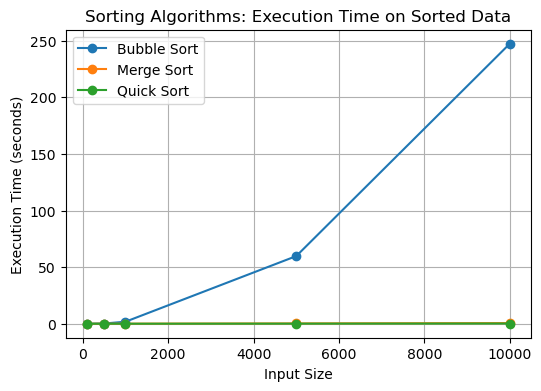

In [39]:
sorted_data = sorting_time_df[
    sorting_time_df["Condition"] == "Sorted"
]

plt.figure(figsize=(6,4))

for algorithm in sorted_data["Algorithm"].unique():
    data = sorted_data[
        sorted_data["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Sorting Algorithms: Execution Time on Sorted Data")
plt.legend()
plt.grid(True)
plt.show()

### Reverse-Sorted graph

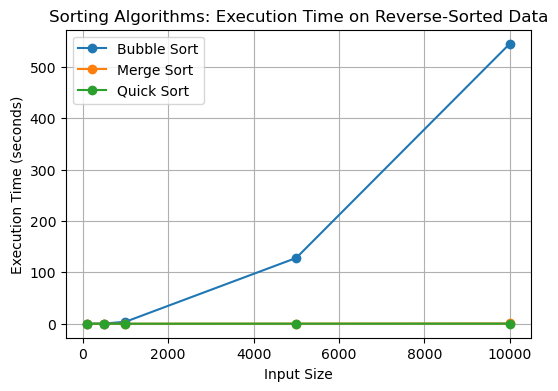

In [41]:
reverse_data = sorting_time_df[
    sorting_time_df["Condition"] == "Reverse-Sorted"
]

plt.figure(figsize=(6,4))

for algorithm in reverse_data["Algorithm"].unique():
    data = reverse_data[
        reverse_data["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Sorting Algorithms: Execution Time on Reverse-Sorted Data")
plt.legend()
plt.grid(True)
plt.show()

### Random Data

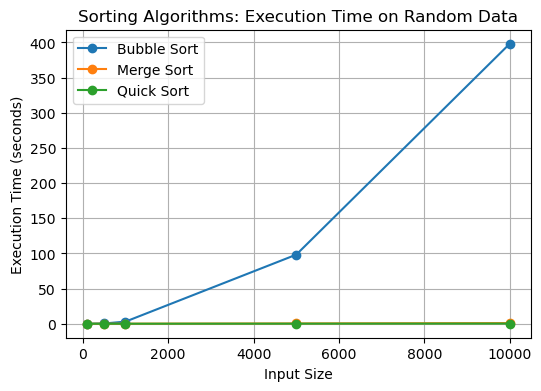

In [42]:
random_data = sorting_time_df[
    sorting_time_df["Condition"] == "Random"
]

plt.figure(figsize=(6,4))

for algorithm in random_data["Algorithm"].unique():
    data = random_data[
        random_data["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Sorting Algorithms: Execution Time on Random Data")
plt.legend()
plt.grid(True)
plt.show()

### Sorting Memory Usage

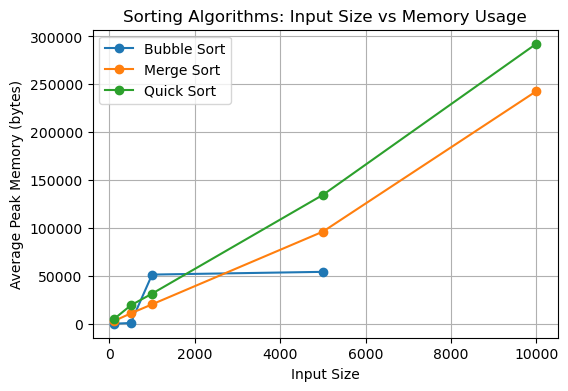

In [44]:
plt.figure(figsize=(6,4))

for algorithm in sorting_memory_df["Algorithm"].unique():
    data = sorting_memory_df[
        sorting_memory_df["Algorithm"] == algorithm
    ]

    # Average memory across the three input conditions
    average_memory = data.groupby("Input Size")["Peak Memory (bytes)"].mean()

    plt.plot(
        average_memory.index,
        average_memory.values,
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Average Peak Memory (bytes)")
plt.title("Sorting Algorithms: Input Size vs Memory Usage")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
sorting_memory_df

,Algorithm,Input Size,Condition,Peak Memory (bytes)
0,Bubble Sort,100,Sorted,31834343
1,Merge Sort,100,Sorted,2032
2,Quick Sort,100,Sorted,2720
3,Bubble Sort,100,Reverse-Sorted,152768
4,Merge Sort,100,Reverse-Sorted,2032
5,Quick Sort,100,Reverse-Sorted,2808
6,Bubble Sort,100,Random,112
7,Merge Sort,100,Random,1824
8,Quick Sort,100,Random,5000
9,Bubble Sort,500,Sorted,236


### Fibonacci: n vs Execution Time

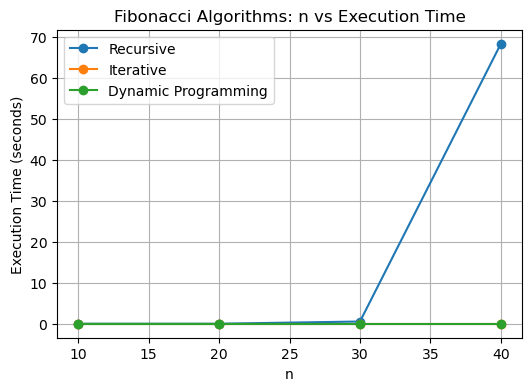

In [47]:
plt.figure(figsize=(6,4))

for algorithm in fibonacci_time_df["Algorithm"].unique():
    data = fibonacci_time_df[
        fibonacci_time_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["n"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("n")
plt.ylabel("Execution Time (seconds)")
plt.title("Fibonacci Algorithms: n vs Execution Time")
plt.legend()
plt.grid(True)
plt.show()

### Fibonacci Memory Usage

In [48]:
import tracemalloc

def measure_fibonacci_memory(fibonacci_function, n):
    tracemalloc.start()
    fibonacci_function(n)
    current_memory, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak_memory

### Fibonacci Memory Experiment

In [49]:
fibonacci_memory_results = []

for n in n_values:
    for algorithm_name, algorithm in fibonacci_algorithms.items():

        peak_memory = measure_fibonacci_memory(algorithm, n)

        fibonacci_memory_results.append({
            "Algorithm": algorithm_name,
            "n": n,
            "Peak Memory (bytes)": peak_memory
        })

print("Fibonacci memory experiment completed!")

Fibonacci memory experiment completed!


### Fibonacci Memory DF

In [51]:
fibonacci_memory_df = pd.DataFrame(fibonacci_memory_results)
fibonacci_memory_df

,Algorithm,n,Peak Memory (bytes)
0,Recursive,10,0
1,Iterative,10,80
2,Dynamic Programming,10,168
3,Recursive,20,160
4,Iterative,20,128
5,Dynamic Programming,20,424
6,Recursive,30,819
7,Iterative,30,128
8,Dynamic Programming,30,824
9,Recursive,40,1744


### Fibonacci Memory Usage Graph

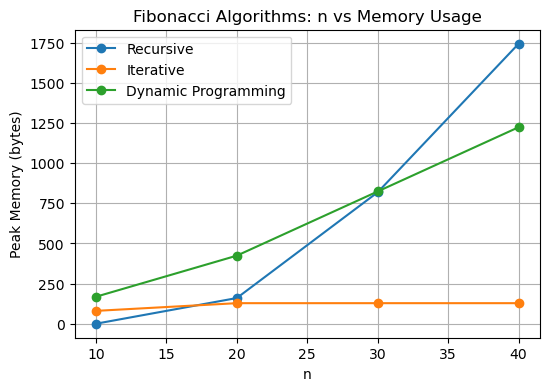

In [53]:
plt.figure(figsize=(6, 4))

for algorithm in fibonacci_memory_df["Algorithm"].unique():
    data = fibonacci_memory_df[
        fibonacci_memory_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["n"],
        data["Peak Memory (bytes)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("n")
plt.ylabel("Peak Memory (bytes)")
plt.title("Fibonacci Algorithms: n vs Memory Usage")
plt.legend()
plt.grid(True)
plt.show()

### Sorting Algorithm Comparison

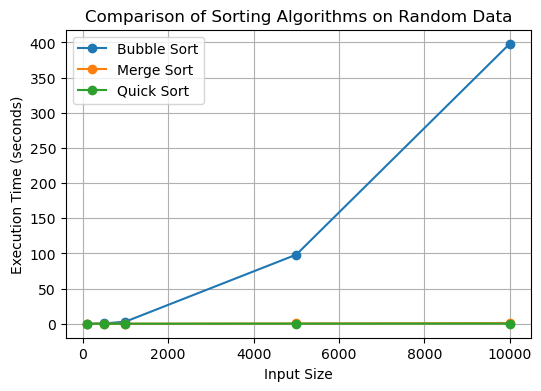

In [54]:
random_data = sorting_time_df[
    sorting_time_df["Condition"] == "Random"
]

plt.figure(figsize=(6,4))

for algorithm in random_data["Algorithm"].unique():
    data = random_data[
        random_data["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Comparison of Sorting Algorithms on Random Data")
plt.legend()
plt.grid(True)
plt.show()

### Fibonacci comparative graph

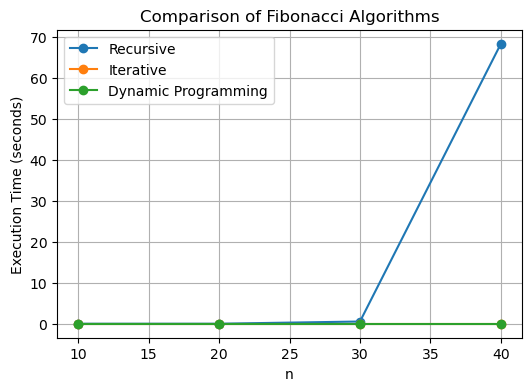

In [55]:
plt.figure(figsize=(6, 4))

for algorithm in fibonacci_time_df["Algorithm"].unique():
    data = fibonacci_time_df[
        fibonacci_time_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["n"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("n")
plt.ylabel("Execution Time (seconds)")
plt.title("Comparison of Fibonacci Algorithms")
plt.legend()
plt.grid(True)
plt.show()